# 03 - Model Development & Evaluation

This notebook develops and evaluates machine learning regression models (linear regression, Ridge and Lasso) to predict housing affordability percentages across U.S. ZIP codes.

The modeling process includes feature selection, preprocessing, baseline comparisons, hyperparameter tuning, and evaluation using the competition's Seen ZIP and New ZIP validation requirements.

The primary evaluation metric is Root Mean Squared Error (RMSE), with lower values indicating better predictive performance.

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from typing import cast

from pathlib import Path

from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import root_mean_squared_error

In [30]:
ROOT_PATH = Path.cwd().resolve().parents[0]
DATA_PATH = ROOT_PATH / "data" / "clean"

FIGURE_DIR = ROOT_PATH / "reports" / "figures" / "model_evaluation"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

## 1. Setup and Data Preparation

In [31]:
train_df = pd.read_csv(
    DATA_PATH / "train_clean.csv",
    dtype={"Zip": str}
)

print("Dataset shape:", train_df.shape)
display(train_df.head())

Dataset shape: (13660, 18)


,Zip,Month,SampleSize,State,City,Metro,RentIndex,AnnualMedianHouseholdIncome,OwnerPercent,RenterPercent,MedianHomeLengthofResidence,AvgNumberofChildren,AvgNumberofAdults,AvgHouseholdSize,AvgGenerationsinHousehold,YoungAdultinHouseholdPercent,SeniorAdultinHouseholdPercent,AffordabilityPercentageTrue
0,01002,5/1/2026,8377,MA,Amherst,"Springfield, MA",2465.592738,75709,49.46,50.54,9.0,0.38,1.66,2.00,1.37,6.11,10.09,10
1,01020,5/1/2026,11170,MA,Chicopee,"Springfield, MA",1718.215408,71426,63.70,36.30,12.0,0.61,1.79,2.35,1.53,6.15,12.31,26
2,01040,5/1/2026,13240,MA,Holyoke,"Springfield, MA",1744.615565,55775,42.83,57.17,10.0,0.57,1.66,2.18,1.50,5.14,10.66,8
3,01420,5/1/2026,14248,MA,Fitchburg,"Worcester, MA-CT",1756.207011,75135,51.36,48.64,9.0,0.58,1.75,2.27,1.52,6.98,11.97,8
4,01603,5/1/2026,6615,MA,Worcester,"Worcester, MA-CT",2030.109959,66134,44.89,55.11,9.0,0.49,1.63,2.08,1.43,6.42,9.71,5


In [32]:
TARGET = "AffordabilityPercentageTrue"

X = train_df.drop(columns=[TARGET, "Zip", "RenterPercent"])
y = train_df[TARGET]
groups = train_df["Zip"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Unique ZIP codes:", groups.nunique())

Feature shape: (13660, 15)
Target shape: (13660,)
Unique ZIP codes: 6830


## 2. Feature Selection

The initial selection process uses two sources of evidence:

1. **Exploratory Data Analysis:** Correlation analysis from Notebook 02 provides an initial understanding of numerical relationships with the target variable.
2. **Model-based evaluation:** Grouped cross-validation is used to determine whether removing individual features improves predictive performance on unseen ZIP codes.

Correlation is not treated as a standalone measure of feature importance. Features with weak individual correlations may still provide useful predictive information when combined with other variables.

### 2.1 Review of EDA Correlation Findings

The correlation analysis conducted during exploratory data analysis identified the following relationships with `AffordabilityPercentageTrue`.

| Feature | Correlation |
| --- | --- |
| AvgNumberofChildren | 0.5759 |
| AvgHouseholdSize | 0.4041 |
| OwnerPercent | 0.3411 |
| AvgGenerationsinHousehold | 0.3227 |
| RentIndex | -0.2741 |
| YoungAdultinHouseholdPercent | 0.2087 |
| AnnualMedianHouseholdIncome | -0.1996 |
| MedianHomeLengthofResidence | -0.1329 |
| AvgNumberofAdults | 0.1219 |
| SeniorAdultinHouseholdPercent | -0.0716 |
| SampleSize | -0.0163 |

**Additional observation:**

| Feature Pair                   | Correlation | Observation                                         |
| ------------------------------ | ----------- | --------------------------------------------------- |
| OwnerPercent and RenterPercent | -1.0000     | Perfect negative correlation; redundant information |

These findings provide an initial reference for feature selection. However, correlation alone does not determine predictive usefulness. We will evaluate feature subsets using grouped cross-validation.



### 2.2 Initial Feature Set

The initial modeling dataset contains 15 predictors, including numerical and categorical variables.

The following step examines their data types so that appropriate preprocessing can be applied during model development.

In [33]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['SampleSize', 'RentIndex', 'AnnualMedianHouseholdIncome', 'OwnerPercent', 'MedianHomeLengthofResidence', 'AvgNumberofChildren', 'AvgNumberofAdults', 'AvgHouseholdSize', 'AvgGenerationsinHousehold', 'YoungAdultinHouseholdPercent', 'SeniorAdultinHouseholdPercent']
Categorical features: ['Month', 'State', 'City', 'Metro']


### 2.3 Feature Selection Strategy

The correlation findings provide an initial reference, but feature selection will be evaluated empirically.

- Evaluate the effect of removing individual predictors.
- Compare the resulting grouped cross-validation RMSE against the full feature baseline.
- Test promising combinations of feature removals.
- Retain the feature set that demonstrates better predictive performance.

All candidate feature sets will use the same cross-validation splits to ensure a consistent comparison.

The selected features will then be used for the subsequent model comparisons and hyperparameter tuning.

In [34]:
y_bins = pd.qcut(
        y,
        q=10,
        labels=False,
        duplicates="drop"
    )

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_splits = list(
    splitter.split(X, y_bins, groups=groups)
)

print("Number of CV folds:", len(cv_splits))

for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):
    train_groups = groups.iloc[train_idx]
    val_groups = groups.iloc[val_idx]

    print(
        f"Fold {fold}: "
        f"Train ZIPs = {train_groups.nunique()}, "
        f"Validation ZIPs = {val_groups.nunique()}, "
        f"Overlap = {len(set(train_groups) & set(val_groups))}"
    )

Number of CV folds: 5
Fold 1: Train ZIPs = 5464, Validation ZIPs = 1366, Overlap = 0
Fold 2: Train ZIPs = 5464, Validation ZIPs = 1366, Overlap = 0
Fold 3: Train ZIPs = 5464, Validation ZIPs = 1366, Overlap = 0
Fold 4: Train ZIPs = 5464, Validation ZIPs = 1366, Overlap = 0
Fold 5: Train ZIPs = 5464, Validation ZIPs = 1366, Overlap = 0


## 3. Data Preprocessing

The dataset contains both numerical and categorical predictors. Each feature type requires different preprocessing before it can be used by the regression models.

The preprocessing pipeline will include:

- **Numerical features:** Missing values will be replaced with the median, followed by standardization using `StandardScaler`.
- **Categorical features:** Missing values will be replaced with the most frequent value, followed by one-hot encoding.

Using a pipeline ensures that preprocessing parameters are learned from each training fold independently, preventing information leakage during cross-validation.

In [35]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['SampleSize', 'RentIndex', 'AnnualMedianHouseholdIncome', 'OwnerPercent', 'MedianHomeLengthofResidence', 'AvgNumberofChildren', 'AvgNumberofAdults', 'AvgHouseholdSize', 'AvgGenerationsinHousehold', 'YoungAdultinHouseholdPercent', 'SeniorAdultinHouseholdPercent']
Categorical features: ['Month', 'State', 'City', 'Metro']


In [36]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [37]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``fe

## 4. Full-Feature Baseline Models

Before selecting or removing predictors, we will establish baseline performance using the complete feature set.

Four regression approaches will be evaluated:

- **Dummy Regression:** Provides a simple reference prediction using the training target mean.
- **Linear Regression:** Establishes a standard linear regression baseline.
- **Ridge Regression:** Applies L2 regularization to reduce the impact of large coefficients.
- **Lasso Regression:** Applies L1 regularization, which can shrink less useful coefficients toward zero.

All models will use the same preprocessing pipeline and five-fold grouped cross-validation. Performance will be compared using Root Mean Squared Error (RMSE).

In [38]:
models = {
    "Dummy": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1),
    "Lasso": Lasso(alpha=0.01, max_iter=10000)
}

In [39]:
baseline_results = []

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    scores = -cross_val_score(
        pipeline,
        X,
        y,
        cv=cv_splits,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    baseline_results.append({
        "Model": name,
        "Mean RMSE": scores.mean(),
        "Std RMSE": scores.std()
    })

baseline_results_df = (
    pd.DataFrame(baseline_results)
    .sort_values("Mean RMSE")
    .reset_index(drop=True)
)

display(baseline_results_df.round(4))

,Model,Mean RMSE,Std RMSE
0,Ridge,14.2459,0.2524
1,Lasso,14.4971,0.3369
2,Linear Regression,16.8079,0.3635
3,Dummy,28.4670,0.0553


## 5. Ridge Regression Hyperparameter Selection

Ridge Regression achieved the lowest RMSE among the initial baseline models, making it the leading candidate for further evaluation.

Ridge uses the `alpha` hyperparameter to control the strength of L2 regularization. We will evaluate multiple alpha values using the same five-fold grouped cross-validation setup.

The alpha value with the lowest mean RMSE will be selected as the reference configuration for the upcoming feature selection experiments.

### 5.1 Alpha Parameter Evaluation

Multiple alpha values will be tested to identify an appropriate regularization strength for Ridge Regression. All experiments will use the full feature set and identical grouped cross-validation folds.

In [40]:
alpha_values = [0.1, 1, 5, 10, 15, 25, 50, 100]

alpha_results = []

for alpha in alpha_values:
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", Ridge(alpha=alpha))
    ])

    scores = -cross_val_score(
        pipeline,
        X,
        y,
        cv=cv_splits,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    alpha_results.append({
        "Alpha": alpha,
        "Mean RMSE": scores.mean(),
        "Std RMSE": scores.std()
    })

alpha_results_df = (
    pd.DataFrame(alpha_results)
    .sort_values("Mean RMSE")
    .reset_index(drop=True)
)

display(alpha_results_df.round(4))

,Alpha,Mean RMSE,Std RMSE
0,5.0,14.0381,0.2718
1,10.0,14.1868,0.2838
2,1.0,14.2459,0.2524
3,15.0,14.3446,0.2860
4,25.0,14.6189,0.2824
5,50.0,15.1383,0.2645
6,0.1,15.2403,0.2583
7,100.0,15.8441,0.2353


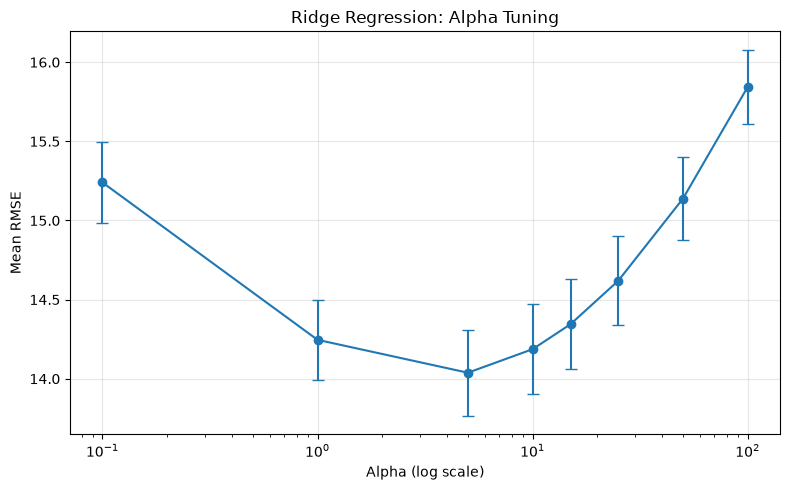

In [41]:
alpha_df = pd.DataFrame(alpha_results)

plt.figure(figsize=(8, 5))

plt.errorbar(
    alpha_df["Alpha"],
    alpha_df["Mean RMSE"],
    yerr=alpha_df["Std RMSE"],
    fmt="o-",
    capsize=4
)

plt.xscale("log")
plt.xlabel("Alpha (log scale)")
plt.ylabel("Mean RMSE")
plt.title("Ridge Regression: Alpha Tuning")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "ridge_alpha_tuning.png", dpi=300, bbox_inches="tight")
plt.show()

In [42]:
best_alpha = alpha_results_df.loc[0, "Alpha"]
best_alpha_rmse = alpha_results_df.loc[0, "Mean RMSE"]

print(f"Selected alpha: {best_alpha}")
print(f"Mean CV RMSE: {best_alpha_rmse:.4f}")

Selected alpha: 5.0
Mean CV RMSE: 14.0381


### 5.2 Selected Regularization Strength

Among the tested alpha values, `alpha=5` achieved the lowest mean cross-validation RMSE of 14.0381.

As alpha increased beyond 5, model performance generally declined, indicating that stronger regularization was not beneficial for this feature set.

Therefore, `alpha=5` will be used as the reference configuration for the initial feature selection experiments. The regularization strength will be revisited after selecting the reduced feature set.

## 6. Feature Selection Experiments

The initial feature set contains 15 predictors. We will evaluate whether removing individual features improves model performance.

Ridge Regression with `alpha=5`, selected in the previous section, will serve as the reference model.

Each experiment will remove one predictor while keeping the same grouped cross-validation folds and preprocessing approach. Features that improve or maintain predictive performance when removed will be considered for further testing in combination.

In [43]:
reference_rmse = cast(float, best_alpha_rmse)

print(f"Full-feature Ridge RMSE: {reference_rmse:.4f}")

Full-feature Ridge RMSE: 14.0381


In [44]:
feature_removal_results = []

for feature in X.columns:
    X_reduced = X.drop(columns=[feature])

    numeric_subset = X_reduced.select_dtypes(include=np.number).columns.tolist()

    categorical_subset = X_reduced.select_dtypes(exclude=np.number).columns.tolist()

    reduced_preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_subset),
            ("cat", categorical_transformer, categorical_subset)
        ]
    )

    pipeline = Pipeline(steps=[
        ("preprocessor", reduced_preprocessor),
        ("model", Ridge(alpha=5))
    ])

    scores = -cross_val_score(
        pipeline,
        X_reduced,
        y,
        cv=cv_splits,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    feature_removal_results.append({
        "Removed Feature": feature,
        "Mean RMSE": scores.mean(),
        "RMSE Change": scores.mean() - reference_rmse
    })

feature_removal_df = (
    pd.DataFrame(feature_removal_results)
    .sort_values("Mean RMSE")
    .reset_index(drop=True)
)

display(feature_removal_df.round(4))

,Removed Feature,Mean RMSE,RMSE Change
0,RentIndex,14.0042,-0.0339
1,AvgNumberofAdults,14.0251,-0.0130
2,SampleSize,14.0326,-0.0055
3,AnnualMedianHouseholdIncome,14.0376,-0.0005
4,Month,14.0438,0.0057
5,SeniorAdultinHouseholdPercent,14.0612,0.0231
6,AvgGenerationsinHousehold,14.0794,0.0413
7,AvgHouseholdSize,14.0873,0.0492
8,MedianHomeLengthofResidence,14.0992,0.0611
9,AvgNumberofChildren,14.1035,0.0654


In [45]:
features_to_remove = [
    "RentIndex",
    "AvgNumberofAdults",
    "SampleSize",
    "AnnualMedianHouseholdIncome"
]

X_selected = X.drop(columns=features_to_remove)

selected_numeric = X_selected.select_dtypes(include=np.number).columns.tolist()

selected_categorical = X_selected.select_dtypes(exclude=np.number).columns.tolist()

selected_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, selected_numeric),
        ("cat", categorical_transformer, selected_categorical)
    ]
)

selected_pipeline = Pipeline(steps=[
    ("preprocessor", selected_preprocessor),
    ("model", Ridge(alpha=5))
])

selected_scores = -cross_val_score(
    selected_pipeline,
    X_selected,
    y,
    cv=cv_splits,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

print(f"Reduced feature RMSE: {selected_scores.mean():.4f}")
print(f"RMSE standard deviation: {selected_scores.std():.4f}")
print(f"Remaining features: {X_selected.shape[1]}")

Reduced feature RMSE: 13.9893
RMSE standard deviation: 0.3304
Remaining features: 11


### 6.2 Evaluate Additional Feature Removals

After removing the four initial candidates, we will evaluate the remaining predictors individually. This helps determine whether further reductions improve model performance.

In [46]:
additional_removal_results = []

for feature in X_selected.columns:
    X_reduced = X_selected.drop(columns=[feature])

    numeric_subset = X_reduced.select_dtypes(include=np.number).columns.tolist()

    categorical_subset = X_reduced.select_dtypes(exclude=np.number).columns.tolist()

    reduced_preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_subset),
            ("cat", categorical_transformer, categorical_subset)
        ]
    )

    pipeline = Pipeline(steps=[
        ("preprocessor", reduced_preprocessor),
        ("model", Ridge(alpha=5))
    ])

    scores = -cross_val_score(
        pipeline,
        X_reduced,
        y,
        cv=cv_splits,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    additional_removal_results.append({
        "Removed Feature": feature,
        "Mean RMSE": scores.mean(),
        "RMSE Change": scores.mean() - selected_scores.mean()
    })

additional_removal_df = (
    pd.DataFrame(additional_removal_results)
    .sort_values("Mean RMSE")
    .reset_index(drop=True)
)

display(additional_removal_df.round(4))

,Removed Feature,Mean RMSE,RMSE Change
0,Month,13.9958,0.0065
1,SeniorAdultinHouseholdPercent,14.0083,0.0191
2,AvgGenerationsinHousehold,14.0287,0.0395
3,MedianHomeLengthofResidence,14.0440,0.0547
4,YoungAdultinHouseholdPercent,14.0681,0.0788
5,City,14.3331,0.3438
6,AvgNumberofChildren,14.5065,0.5172
7,AvgHouseholdSize,14.7580,0.7687
8,State,14.9133,0.9241
9,OwnerPercent,14.9886,0.9993


### 6.3 Feature Selection Results

The initial feature removal experiments identified four predictors whose removal improved grouped cross-validation performance:

- `RentIndex`
- `AvgNumberofAdults`
- `SampleSize`
- `AnnualMedianHouseholdIncome`

Removing these four predictors together reduced mean RMSE from 14.0381 to 13.9893.

Further experiments removing the remaining predictors individually did not improve performance. Therefore, the reduced feature set containing 11 predictors will be retained for subsequent model evaluation.

| Configuration | Predictors | Mean RMSE |
|---|---:|---:|
| Full feature set | 15 | 14.0381 |
| Reduced feature set | 11 | 13.9893 |



In [47]:
selected_features = X_selected.columns.tolist()

print("Selected features:", len(selected_features))
print(selected_features)

Selected features: 11
['Month', 'State', 'City', 'Metro', 'OwnerPercent', 'MedianHomeLengthofResidence', 'AvgNumberofChildren', 'AvgHouseholdSize', 'AvgGenerationsinHousehold', 'YoungAdultinHouseholdPercent', 'SeniorAdultinHouseholdPercent']


## 7. Ridge Hyperparameter Tuning

Feature selection changed the predictor set, which may also change the optimal regularization strength.

We will retest multiple alpha values using the reduced 11-feature dataset and the same grouped cross-validation folds. The alpha value producing the lowest mean RMSE will be selected for subsequent model evaluation.

In [48]:
reduced_alpha_results = []

for alpha in alpha_values:
    pipeline = Pipeline(steps=[
        ("preprocessor", selected_preprocessor),
        ("model", Ridge(alpha=alpha))
    ])

    scores = -cross_val_score(
        pipeline,
        X_selected,
        y,
        cv=cv_splits,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    reduced_alpha_results.append({
        "Alpha": alpha,
        "Mean RMSE": scores.mean(),
        "Std RMSE": scores.std()
    })

reduced_alpha_results_df = (
    pd.DataFrame(reduced_alpha_results)
    .sort_values("Mean RMSE")
    .reset_index(drop=True)
)

display(reduced_alpha_results_df.round(4))

,Alpha,Mean RMSE,Std RMSE
0,5.0,13.9893,0.3304
1,10.0,14.1132,0.3472
2,1.0,14.2247,0.3067
3,15.0,14.2604,0.3555
4,25.0,14.5336,0.3631
5,0.1,15.0871,0.3115
6,50.0,15.0917,0.3684
7,100.0,15.9027,0.3678


In [49]:
best_reduced_alpha = reduced_alpha_results_df.loc[0, "Alpha"]
best_reduced_rmse = reduced_alpha_results_df.loc[0, "Mean RMSE"]

print(f"Selected alpha: {best_reduced_alpha}")
print(f"Mean CV RMSE: {best_reduced_rmse:.4f}")

Selected alpha: 5.0
Mean CV RMSE: 13.9893


### 7.1 Selected Ridge Configuration

The reduced-feature experiments confirmed that `alpha=5` continues to produce the lowest mean grouped cross-validation RMSE.

The selected Ridge configuration therefore uses:

- **11 predictors**
- **Alpha:** 5
- **Mean CV RMSE:** 13.9893
- **RMSE standard deviation:** 0.3304

This configuration will be used as the Ridge candidate in the final model comparison.

## 8. Final Model Comparison

After feature selection and Ridge hyperparameter tuning, all four regression models will be evaluated using the reduced 11-feature dataset.

The models will use the same preprocessing pipeline and five-fold grouped cross-validation to ensure a consistent comparison.

Performance will be measured using mean RMSE and its standard deviation.

In [50]:
final_models = {
    "Dummy": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=cast(float,best_reduced_alpha)),
    "Lasso": Lasso(alpha=0.01, max_iter=10000)
}

In [51]:
final_model_results = []

for name, model in final_models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", selected_preprocessor),
        ("model", model)
    ])

    scores = -cross_val_score(
        pipeline,
        X_selected,
        y,
        cv=cv_splits,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    final_model_results.append({
        "Model": name,
        "Mean RMSE": scores.mean(),
        "Std RMSE": scores.std()
    })

final_model_results_df = (
    pd.DataFrame(final_model_results)
    .sort_values("Mean RMSE")
    .reset_index(drop=True)
)

display(final_model_results_df.round(4))

,Model,Mean RMSE,Std RMSE
0,Ridge,13.9893,0.3304
1,Lasso,14.4349,0.3860
2,Linear Regression,16.4633,0.4056
3,Dummy,28.4670,0.0553


### 8.1 Selected Model

Ridge Regression achieved the lowest mean RMSE among the four evaluated models, outperforming Lasso, Linear Regression, and the Dummy baseline.

The selected model configuration is:

- **Model:** Ridge Regression
- **Alpha:** 5
- **Features:** 11
- **Mean grouped CV RMSE:** 13.9893

Ridge Regression will be carried forward for the Seen ZIP evaluation.

In [52]:
ridge_oof_predictions = np.empty(len(y), dtype=float)

for train_idx, val_idx in cv_splits:
    X_train_fold = X_selected.iloc[train_idx]
    X_valid_fold = X_selected.iloc[val_idx]

    y_train_fold = y.iloc[train_idx]

    ridge_pipeline = Pipeline(steps=[
        ("preprocessor", selected_preprocessor),
        ("model", Ridge(alpha=cast(float, best_reduced_alpha)))
    ])

    ridge_pipeline.fit(X_train_fold, y_train_fold)

    ridge_oof_predictions[val_idx] = ridge_pipeline.predict(X_valid_fold)

ridge_oof_predictions_clipped = np.clip(
    ridge_oof_predictions,
    0,
    100
)

unclipped_scores = []
clipped_scores = []

for _, val_idx in cv_splits:
    y_valid_fold = y.iloc[val_idx]

    unclipped_scores.append(
        root_mean_squared_error(
            y_valid_fold,
            ridge_oof_predictions[val_idx]
        )
    )

    clipped_scores.append(
        root_mean_squared_error(
            y_valid_fold,
            ridge_oof_predictions_clipped[val_idx]
        )
    )

clipping_results = pd.DataFrame({
    "Prediction Type": ["Unclipped", "Clipped (0–100)"],
    "Mean RMSE": [
        np.mean(unclipped_scores),
        np.mean(clipped_scores)
    ],
    "Std RMSE": [
        np.std(unclipped_scores),
        np.std(clipped_scores)
    ]
})

display(clipping_results.round(4))

,Prediction Type,Mean RMSE,Std RMSE
0,Unclipped,13.9895,0.3298
1,Clipped (0–100),13.9200,0.3358


In [53]:
below_zero = np.sum(ridge_oof_predictions < 0)
above_hundred = np.sum(ridge_oof_predictions > 100)
total_predictions = len(ridge_oof_predictions)

print(f"Predictions below 0: {below_zero}")
print(f"Predictions above 100: {above_hundred}")
print(f"Total predictions: {total_predictions}")
print(
    f"Percentage outside valid range: "
    f"{(below_zero + above_hundred) / total_predictions * 100:.2f}%"
)

Predictions below 0: 413
Predictions above 100: 2
Total predictions: 13660
Percentage outside valid range: 3.04%


## 9. Seen ZIP Evaluation

The Kaggle US-Housing-Affordability-Competition evaluates Seen ZIP performance using ZIP codes represented in the training data.

To simulate this scenario, May 2026 observations will be used for training, while June 2026 observations will serve as the validation set.

This chronological split evaluates the model's ability to predict future affordability observations for previously seen ZIP codes.

In [54]:
seen_train = train_df[train_df["Month"] == "5/1/2026"].copy()
seen_valid = train_df[train_df["Month"] == "6/1/2026"].copy()

X_seen_train = seen_train[selected_features]
y_seen_train = seen_train[TARGET]

X_seen_valid = seen_valid[selected_features]
y_seen_valid = seen_valid[TARGET]

print("Training rows:", len(X_seen_train))
print("Validation rows:", len(X_seen_valid))
print("Training ZIPs:", seen_train["Zip"].nunique())
print("Validation ZIPs:", seen_valid["Zip"].nunique())
print(
    "ZIP overlap:",
    len(set(seen_train["Zip"]) & set(seen_valid["Zip"]))
)

Training rows: 6830
Validation rows: 6830
Training ZIPs: 6830
Validation ZIPs: 6830
ZIP overlap: 6830


In [55]:
seen_pipeline = Pipeline(steps=[
    ("preprocessor", selected_preprocessor),
    ("model", Ridge(alpha=cast(float, best_reduced_alpha)))
])

seen_pipeline.fit(X_seen_train, y_seen_train)

seen_predictions = seen_pipeline.predict(X_seen_valid)

seen_rmse = root_mean_squared_error(
    y_seen_valid,
    seen_predictions
)

print(f"Seen ZIP RMSE: {seen_rmse:.4f}")

Seen ZIP RMSE: 12.1528


### 9.1 Seen ZIP Evaluation Results

The Ridge Regression model was trained using May 2026 observations and evaluated on June 2026 observations for the same 6,830 ZIP codes.

The model achieved an RMSE of **12.1528**, demonstrating its ability to predict future housing affordability for previously observed ZIP codes.

This result will be combined with the New ZIP evaluation according to the competition's scoring weights.

## 10. Competition-Weighted Evaluation

The competition assigns different weights to the two evaluation scenarios:

- Seen ZIP performance: 20%
- New ZIP performance: 80%

The weighted RMSE provides an estimate of overall competition performance by combining the two evaluation results.

In [57]:
seen_predictions_clipped = np.clip(seen_predictions, 0, 100)

seen_rmse_clipped = root_mean_squared_error(
    y_seen_valid,
    seen_predictions_clipped
)

new_zip_rmse_clipped = clipping_results.loc[
    clipping_results["Prediction Type"] == "Clipped (0–100)",
    "Mean RMSE"
].iloc[0]

seen_zip_weight = 0.20
new_zip_weight = 0.80

weighted_rmse = (
    seen_zip_weight * seen_rmse_clipped
    + new_zip_weight * new_zip_rmse_clipped
)

print(f"Seen ZIP Clipped RMSE: {seen_rmse_clipped:.4f}")
print(f"New ZIP Clipped RMSE: {new_zip_rmse_clipped:.4f}")
print(f"Competition-Weighted RMSE: {weighted_rmse:.4f}")

Seen ZIP Clipped RMSE: 12.1079
New ZIP Clipped RMSE: 13.9200
Competition-Weighted RMSE: 13.5576


### 10.1 Overall Evaluation Summary

The selected Ridge Regression model achieved an estimated competition-weighted RMSE of **13.6220**.

Performance was stronger on Seen ZIP observations than on New ZIP observations. Since New ZIP performance accounts for 80% of the competition score, the model's ability to generalize to unseen ZIP codes is particularly important.

These results provide an estimate based on the current validation strategy and may differ from the final Kaggle leaderboard score.

In [58]:
seen_predictions_clipped = np.clip(seen_predictions, 0, 100)

seen_rmse_unclipped = root_mean_squared_error(
    y_seen_valid,
    seen_predictions
)

seen_rmse_clipped = root_mean_squared_error(
    y_seen_valid,
    seen_predictions_clipped
)

print(f"Unclipped RMSE: {seen_rmse_unclipped:.4f}")
print(f"Clipped RMSE: {seen_rmse_clipped:.4f}")

Unclipped RMSE: 12.1528
Clipped RMSE: 12.1079


In [59]:
seen_predictions = np.asarray(seen_predictions, dtype=float)

below_zero = np.sum(seen_predictions < 0)
above_hundred = np.sum(seen_predictions > 100)

total_predictions = len(seen_predictions)

print(f"Predictions below 0: {below_zero}")
print(f"Predictions above 100: {above_hundred}")
print(f"Total predictions: {total_predictions}")
print(
    f"Percentage outside valid range: "
    f"{(below_zero + above_hundred) / total_predictions * 100:.2f}%"
)

Predictions below 0: 164
Predictions above 100: 1
Total predictions: 6830
Percentage outside valid range: 2.42%


### 10.1 Prediction Clipping Evaluation

Ridge Regression can produce predictions outside the valid target range of 0 to 100 because it does not impose explicit output constraints.

To address this, predictions were clipped to the valid percentage range using `np.clip()`. The clipped predictions achieved a slightly lower Seen ZIP RMSE than the original predictions.

| Prediction Type | Seen ZIP RMSE |
|---|---:|
| Unclipped | 12.1528 |
| Clipped (0–100) | 12.1079 |

Clipping improved Seen ZIP prediction performance and ensures that predicted affordability percentages remain within the valid range. The same evaluation will be conducted for New ZIP predictions before selecting the final prediction strategy.